In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [55]:
DATA_PATH = "/kaggle/input/datasets/aiwithyaswanth/extention-of-z-alizadeh-sani-dataset-xlsx/extention of Z-Alizadeh sani   dataset (2).xlsx"

df = pd.read_excel(
    DATA_PATH,
    sheet_name="Sheet 1 - Table 1"
)

print("Dataset loaded successfully!")



Dataset loaded successfully!


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 59 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    303 non-null    int64  
 1   Weight                 303 non-null    int64  
 2   Length                 303 non-null    int64  
 3   Sex                    303 non-null    object 
 4   BMI                    303 non-null    float64
 5   DM                     303 non-null    int64  
 6   HTN                    303 non-null    int64  
 7   Current Smoker         303 non-null    int64  
 8   EX-Smoker              303 non-null    int64  
 9   FH                     303 non-null    int64  
 10  Obesity                303 non-null    object 
 11  CRF                    303 non-null    object 
 12  CVA                    303 non-null    object 
 13  Airway disease         303 non-null    object 
 14  Thyroid Disease        303 non-null    object 
 15  CHF   

In [57]:
df.shape

(303, 59)

In [58]:
df.head()

,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,LAD,LCX,RCA,Cath
0,53,90,175,Male,29.387755,0,1,1,0,0,...,39,52,261,50,0,N,Stenotic,Normal,Stenotic,CAD
1,67,70,157,Fmale,28.398718,0,1,0,0,0,...,38,55,165,40,4,N,Stenotic,Stenotic,Normal,CAD
2,54,54,164,Male,20.077335,0,0,1,0,0,...,38,60,230,40,2,mild,Stenotic,Normal,Normal,CAD
3,66,67,158,Fmale,26.838648,0,1,0,0,0,...,18,72,742,55,0,Severe,Normal,Normal,Normal,Normal
4,50,87,153,Fmale,37.165193,0,1,0,0,0,...,55,39,274,50,0,Severe,Normal,Normal,Normal,Normal


In [59]:
targets = ["Cath", "LAD", "LCX", "RCA"]

for target in targets:
    print(f"\n{target}")
    print(df[target].value_counts())


Cath
Cath
CAD       216
Normal     87
Name: count, dtype: int64

LAD
LAD
Stenotic    177
Normal      126
Name: count, dtype: int64

LCX
LCX
Normal      184
Stenotic    119
Name: count, dtype: int64

RCA
RCA
Normal      189
Stenotic    114
Name: count, dtype: int64


In [60]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nTarget columns:")
for col in ["Cath", "LAD", "LCX", "RCA"]:
    print(col, "→", col in df.columns)

Rows: 303
Columns: 59

Target columns:
Cath → True
LAD → True
LCX → True
RCA → True


In [61]:
pd.set_option("display.max_rows", 100)

for i, col in enumerate(df.columns):
    print(f"{i:2d}. {col}")

 0. Age
 1. Weight
 2. Length
 3. Sex
 4. BMI
 5. DM
 6. HTN
 7. Current Smoker
 8. EX-Smoker
 9. FH
10. Obesity
11. CRF
12. CVA
13. Airway disease
14. Thyroid Disease
15. CHF
16. DLP
17. BP
18. PR
19. Edema
20. Weak Peripheral Pulse
21. Lung rales
22. Systolic Murmur
23. Diastolic Murmur
24. Typical Chest Pain
25. Dyspnea
26. Function Class
27. Atypical
28. Nonanginal
29. Exertional CP
30. LowTH Ang
31. Q Wave
32. St Elevation
33. St Depression
34. Tinversion
35. LVH
36. Poor R Progression
37. BBB
38. FBS
39. CR
40. TG
41. LDL
42. HDL
43. BUN
44. ESR
45. HB
46. K
47. Na
48. WBC
49. Lymph
50. Neut
51. PLT
52. EF-TTE
53. Region RWMA
54. VHD
55. LAD
56. LCX
57. RCA
58. Cath


In [62]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,303.0,NaN,NaN,NaN,58.89769,10.392278,30.0,51.0,58.0,66.0,86.0
Weight,303.0,NaN,NaN,NaN,73.831683,11.987358,48.0,65.0,74.0,81.0,120.0
Length,303.0,NaN,NaN,NaN,164.716172,9.327661,140.0,158.0,165.0,171.0,188.0
Sex,303,2,Male,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BMI,303.0,NaN,NaN,NaN,27.248339,4.098865,18.115413,24.51438,26.77551,29.411765,40.900658
DM,303.0,NaN,NaN,NaN,0.29703,0.457706,0.0,0.0,0.0,1.0,1.0
HTN,303.0,NaN,NaN,NaN,0.590759,0.492507,0.0,0.0,1.0,1.0,1.0
Current Smoker,303.0,NaN,NaN,NaN,0.207921,0.406491,0.0,0.0,0.0,0.0,1.0
EX-Smoker,303.0,NaN,NaN,NaN,0.033003,0.178941,0.0,0.0,0.0,0.0,1.0
FH,303.0,NaN,NaN,NaN,0.158416,0.365734,0.0,0.0,0.0,0.0,1.0


In [63]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    "Column": missing.index,
    "Missing": missing.values,
    "Missing_Percentage": (missing.values / len(df) * 100)
})

missing_df = missing_df.sort_values(
    "Missing",
    ascending=False
)

missing_df.head(58)

,Column,Missing,Missing_Percentage
0,Age,0,0.0
1,Weight,0,0.0
2,Length,0,0.0
3,Sex,0,0.0
4,BMI,0,0.0
5,DM,0,0.0
6,HTN,0,0.0
7,Current Smoker,0,0.0
8,EX-Smoker,0,0.0
9,FH,0,0.0


In [64]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


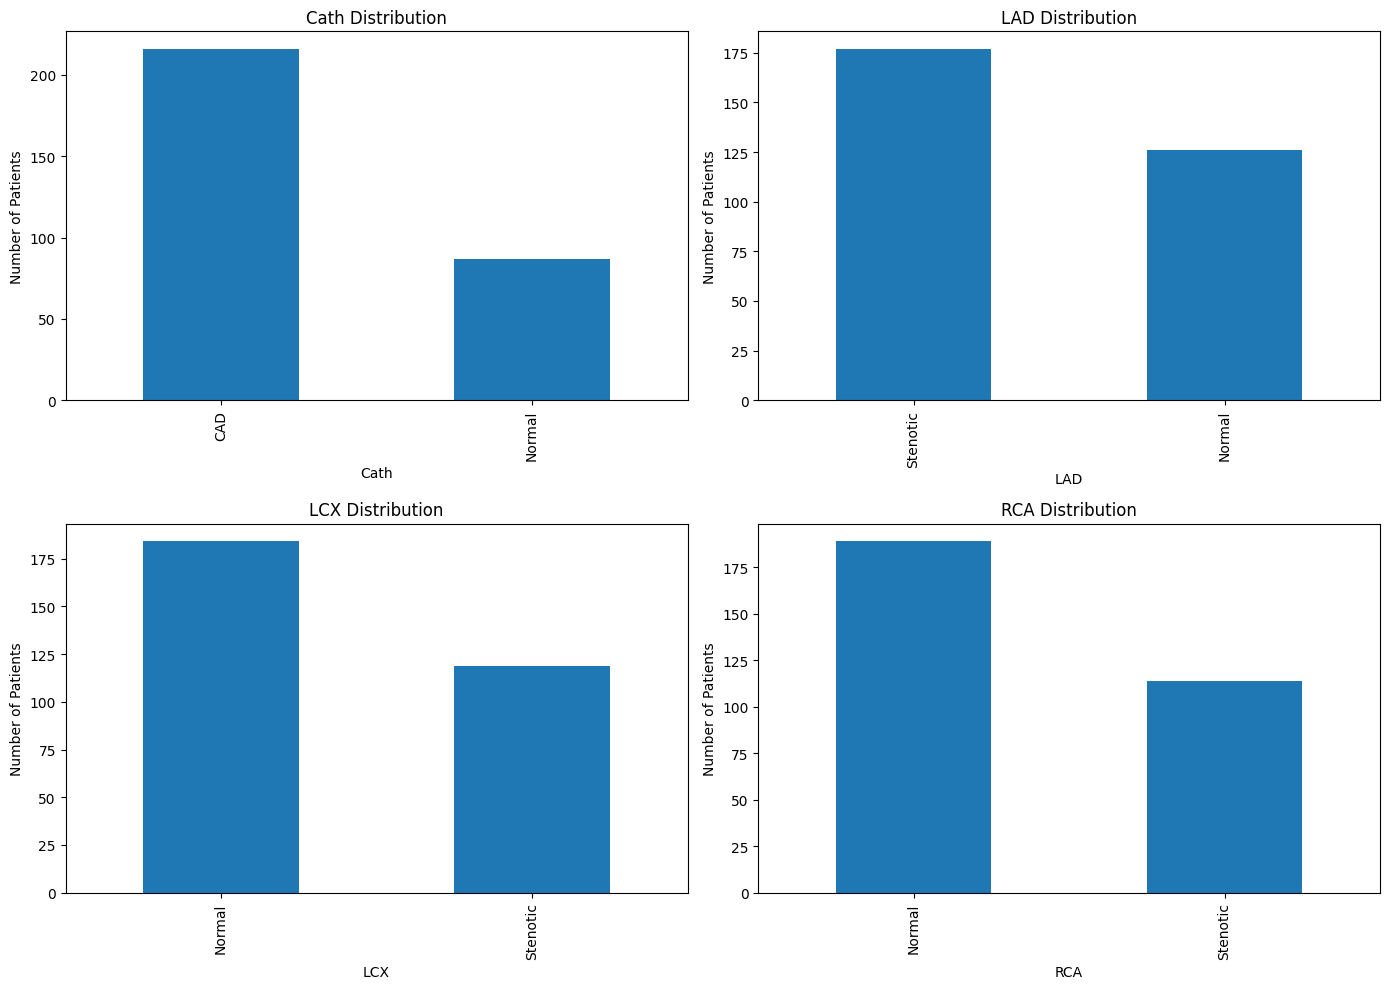

In [65]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, target in zip(axes.ravel(), targets):
    df[target].value_counts().plot(
        kind="bar",
        ax=ax
    )
    ax.set_title(f"{target} Distribution")
    ax.set_xlabel(target)
    ax.set_ylabel("Number of Patients")

plt.tight_layout()
plt.show()

In [66]:
# Identify numerical and categorical columns

numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical columns:", len(categorical_columns))
print(categorical_columns)

Numerical columns: 34
['Age', 'Weight', 'Length', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'BP', 'PR', 'Edema', 'Typical Chest Pain', 'Function Class', 'Q Wave', 'St Elevation', 'St Depression', 'Tinversion', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR', 'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA']

Categorical columns: 25
['Sex', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP', 'LowTH Ang', 'LVH', 'Poor R Progression', 'BBB', 'VHD', 'LAD', 'LCX', 'RCA', 'Cath']


In [67]:
for col in categorical_columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print(df[col].value_counts(dropna=False))


Column: Sex
Sex
Male     176
Fmale    127
Name: count, dtype: int64

Column: Obesity
Obesity
Y    211
N     92
Name: count, dtype: int64

Column: CRF
CRF
N    297
Y      6
Name: count, dtype: int64

Column: CVA
CVA
N    298
Y      5
Name: count, dtype: int64

Column: Airway disease
Airway disease
N    292
Y     11
Name: count, dtype: int64

Column: Thyroid Disease
Thyroid Disease
N    296
Y      7
Name: count, dtype: int64

Column: CHF
CHF
N    302
Y      1
Name: count, dtype: int64

Column: DLP
DLP
N    191
Y    112
Name: count, dtype: int64

Column: Weak Peripheral Pulse
Weak Peripheral Pulse
N    298
Y      5
Name: count, dtype: int64

Column: Lung rales
Lung rales
N    292
Y     11
Name: count, dtype: int64

Column: Systolic Murmur
Systolic Murmur
N    262
Y     41
Name: count, dtype: int64

Column: Diastolic Murmur
Diastolic Murmur
N    294
Y      9
Name: count, dtype: int64

Column: Dyspnea
Dyspnea
N    169
Y    134
Name: count, dtype: int64

Column: Atypical
Atypical
N    210
Y

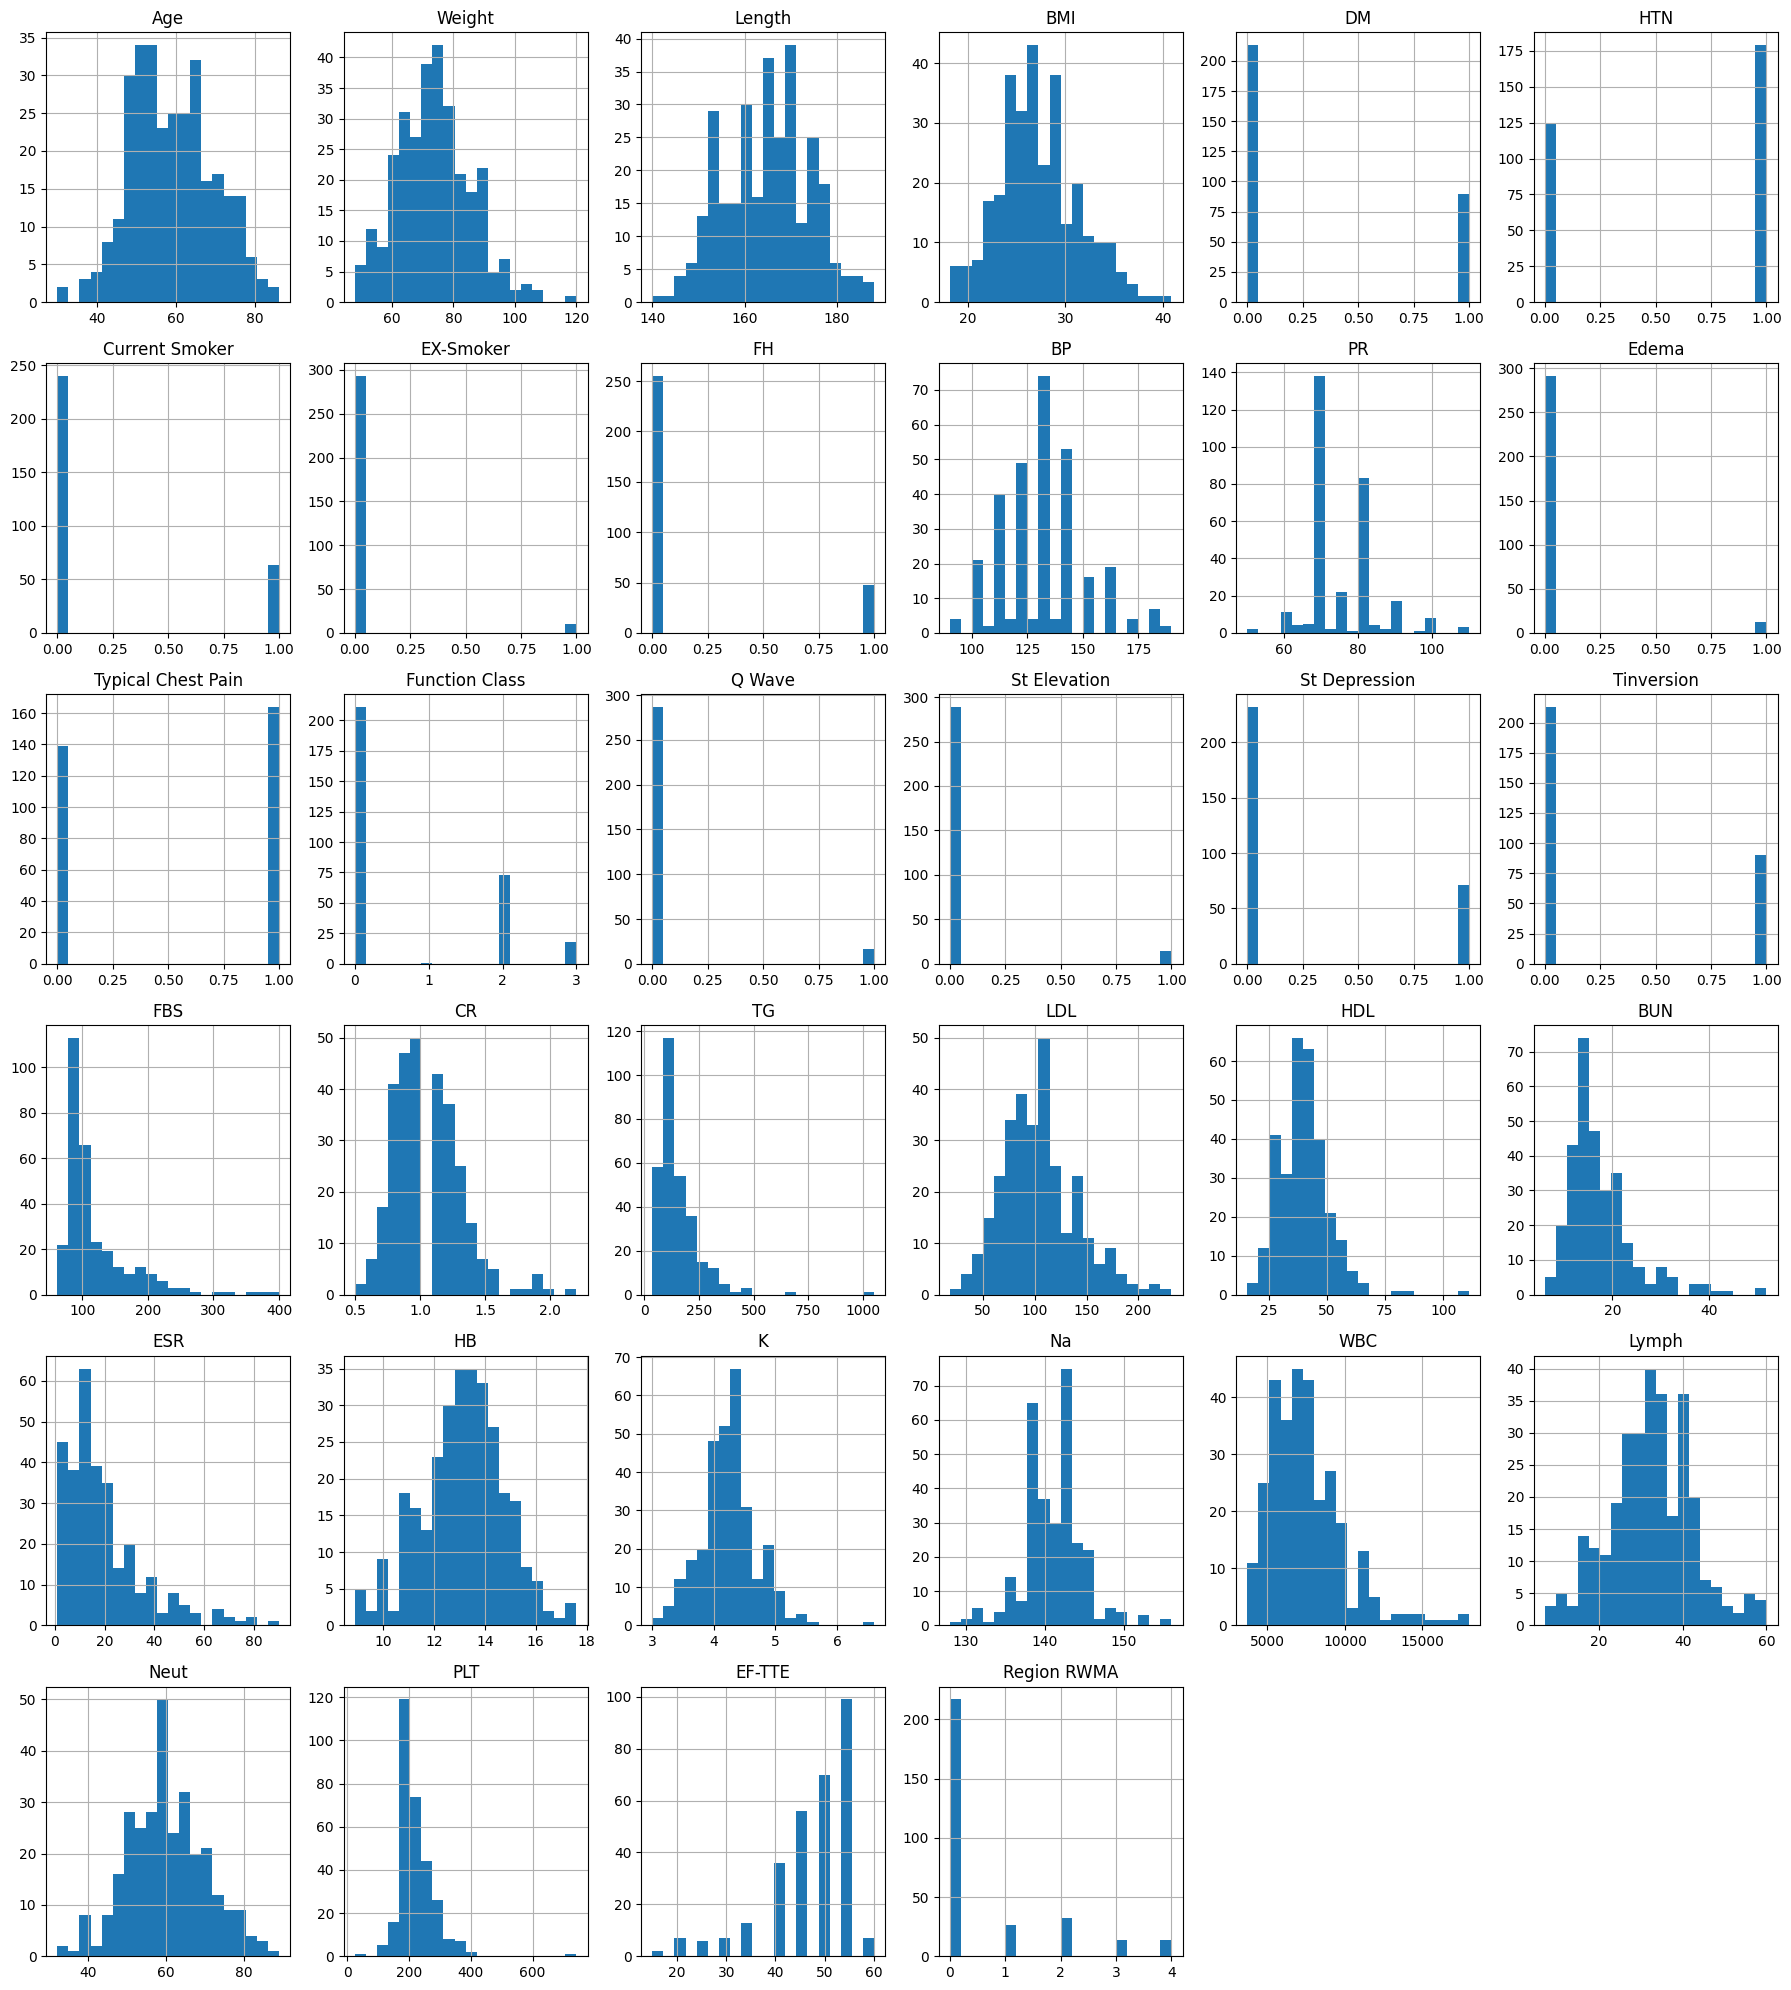

In [68]:
df[numerical_columns].hist(
    figsize=(18, 20),
    bins=20
)

plt.tight_layout()
plt.show()

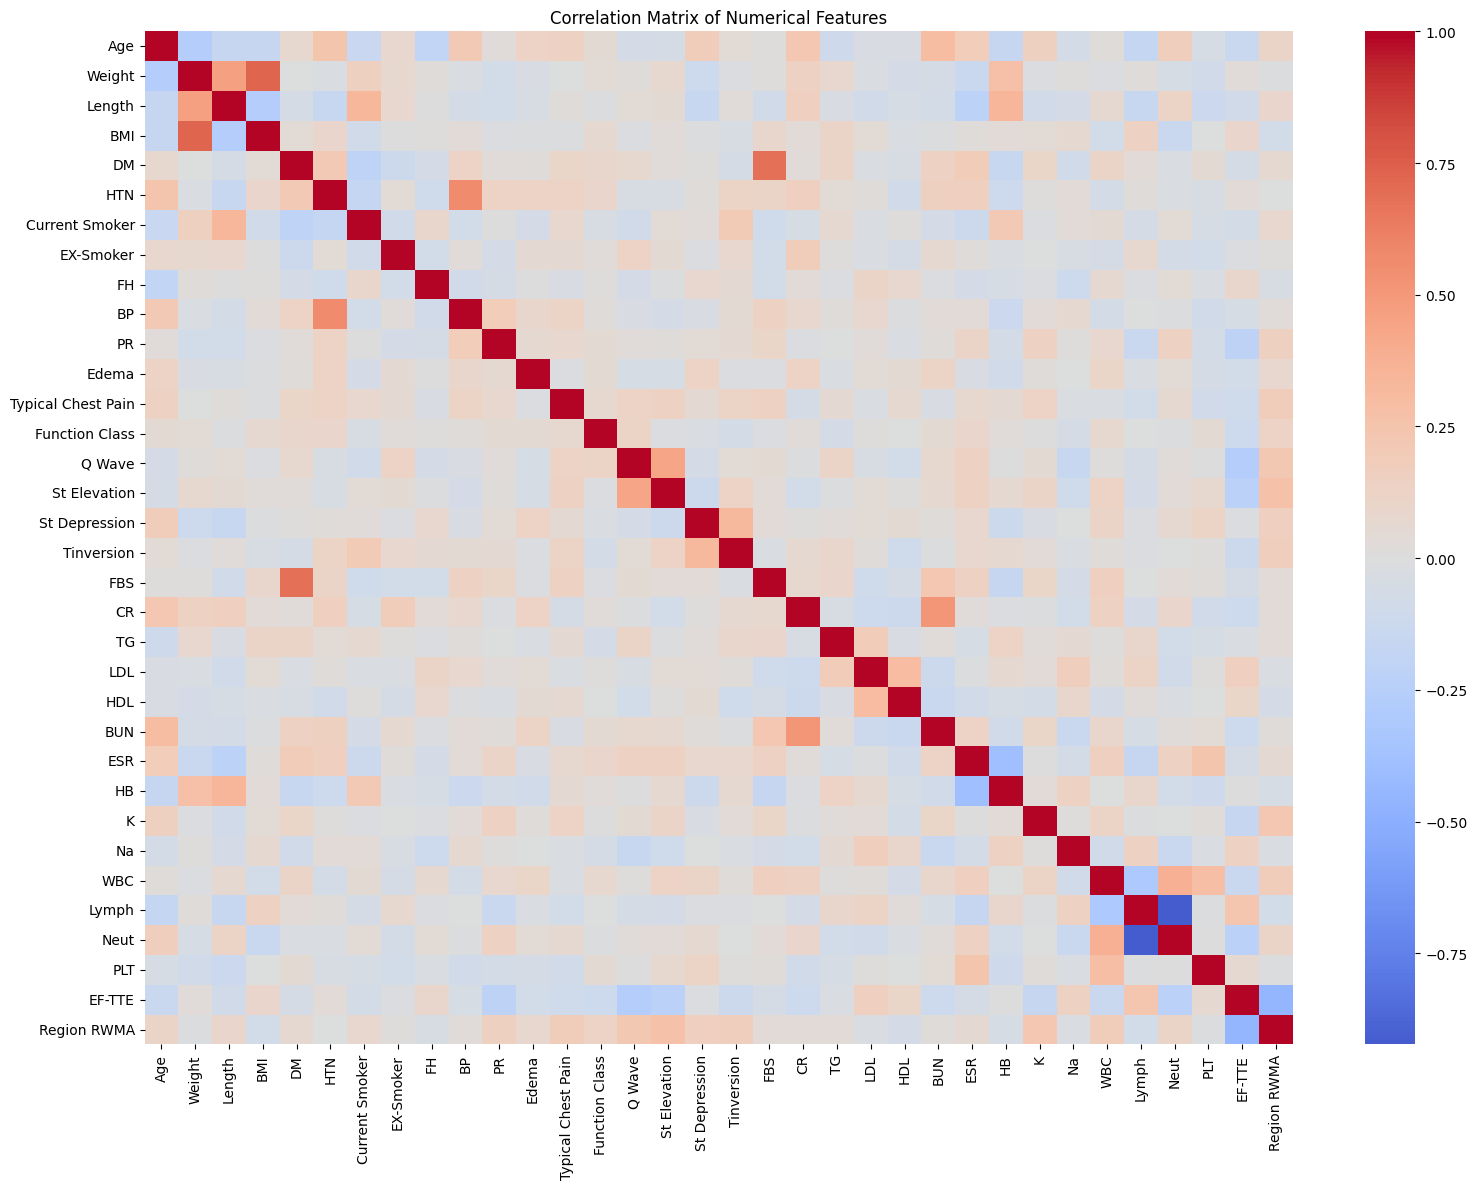

In [69]:
plt.figure(figsize=(16, 12))

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [70]:
print(df["Cath"].value_counts())

print("\nPercentages:")
print(df["Cath"].value_counts(normalize=True) * 100)

Cath
CAD       216
Normal     87
Name: count, dtype: int64

Percentages:
Cath
CAD       71.287129
Normal    28.712871
Name: proportion, dtype: float64


In [71]:
vessel_targets = ["LAD", "LCX", "RCA"]

for target in vessel_targets:
    print(f"\n{target}")
    print(df[target].value_counts())
    print(df[target].value_counts(normalize=True) * 100)


LAD
LAD
Stenotic    177
Normal      126
Name: count, dtype: int64
LAD
Stenotic    58.415842
Normal      41.584158
Name: proportion, dtype: float64

LCX
LCX
Normal      184
Stenotic    119
Name: count, dtype: int64
LCX
Normal      60.726073
Stenotic    39.273927
Name: proportion, dtype: float64

RCA
RCA
Normal      189
Stenotic    114
Name: count, dtype: int64
RCA
Normal      62.376238
Stenotic    37.623762
Name: proportion, dtype: float64


In [72]:
important_features = [
    "Age",
    "BMI",
    "BP",
    "PR",
    "FBS",
    "CR",
    "TG",
    "LDL",
    "HDL",
    "EF-TTE",
    "Region RWMA"
]

available_features = [
    col for col in important_features
    if col in df.columns
]

print(available_features)

['Age', 'BMI', 'BP', 'PR', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'EF-TTE', 'Region RWMA']


In [73]:
df.groupby("Cath")[available_features].mean(numeric_only=True).T

Cath,CAD,Normal
Age,61.250000,53.057471
BMI,27.045279,27.752487
BP,132.407407,122.471264
PR,76.092593,72.781609
FBS,125.967593,102.344828
CR,1.070139,1.019540
TG,159.069444,128.678161
LDL,104.115741,105.954023
HDL,39.949074,40.941379
EF-TTE,45.907407,50.517241


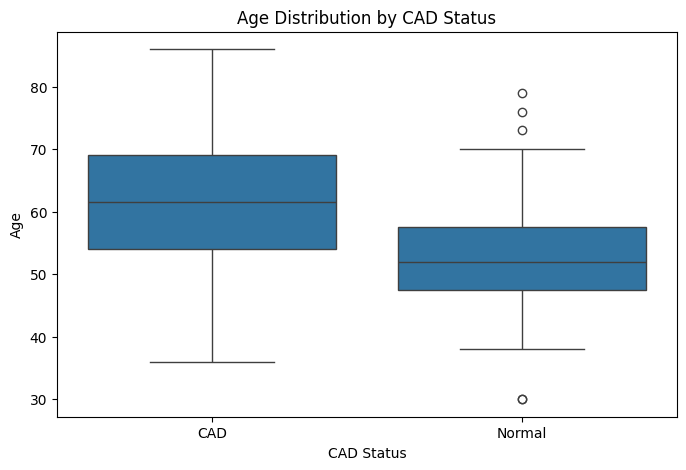

In [74]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Cath",
    y="Age"
)

plt.title("Age Distribution by CAD Status")
plt.xlabel("CAD Status")
plt.ylabel("Age")

plt.show()

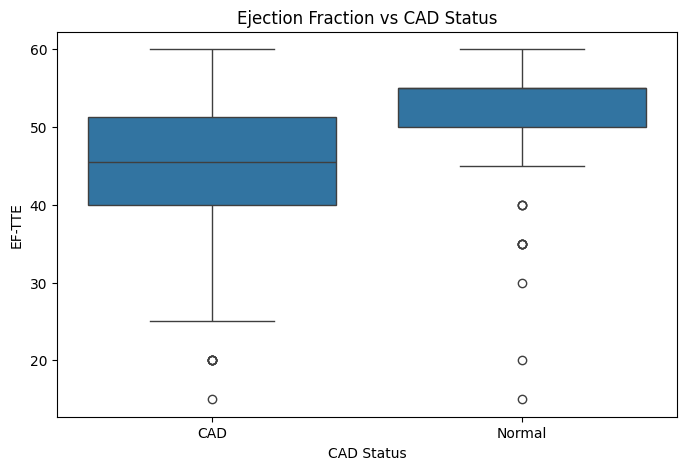

In [75]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Cath",
    y="EF-TTE"
)

plt.title("Ejection Fraction vs CAD Status")
plt.xlabel("CAD Status")
plt.ylabel("EF-TTE")

plt.show()

In [76]:
TARGETS = ["Cath", "LAD", "LCX", "RCA"]

print("Targets:")
for target in TARGETS:
    print("-", target)

Targets:
- Cath
- LAD
- LCX
- RCA


In [77]:
LEAKAGE_COLUMNS = ["Cath", "LAD", "LCX", "RCA"]

print("Columns excluded from model inputs:")
print(LEAKAGE_COLUMNS)

Columns excluded from model inputs:
['Cath', 'LAD', 'LCX', 'RCA']


In [78]:
X = df.drop(columns=LEAKAGE_COLUMNS)

print("Feature matrix shape:", X.shape)
print("\nFeatures:")
print(X.columns.tolist())

Feature matrix shape: (303, 55)

Features:
['Age', 'Weight', 'Length', 'Sex', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'BP', 'PR', 'Edema', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Typical Chest Pain', 'Dyspnea', 'Function Class', 'Atypical', 'Nonanginal', 'Exertional CP', 'LowTH Ang', 'Q Wave', 'St Elevation', 'St Depression', 'Tinversion', 'LVH', 'Poor R Progression', 'BBB', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR', 'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA', 'VHD']


In [79]:
for target in TARGETS:
    print(f"\n===== {target} =====")
    print(df[target].unique())


===== Cath =====
['CAD' 'Normal']

===== LAD =====
['Stenotic' 'Normal']

===== LCX =====
['Normal' 'Stenotic']

===== RCA =====
['Stenotic' 'Normal']


In [80]:
for target in TARGETS:
    print(f"\n===== {target} =====")
    print(df[target].value_counts(dropna=False))


===== Cath =====
Cath
CAD       216
Normal     87
Name: count, dtype: int64

===== LAD =====
LAD
Stenotic    177
Normal      126
Name: count, dtype: int64

===== LCX =====
LCX
Normal      184
Stenotic    119
Name: count, dtype: int64

===== RCA =====
RCA
Normal      189
Stenotic    114
Name: count, dtype: int64


In [81]:
y = {}

y["Cath"] = df["Cath"].map({
    "CAD": 1,
    "Normal": 0
})

y["LAD"] = df["LAD"].map({
    "Stenotic": 1,
    "Normal": 0
})

y["LCX"] = df["LCX"].map({
    "Stenotic": 1,
    "Normal": 0
})

y["RCA"] = df["RCA"].map({
    "Stenotic": 1,
    "Normal": 0
})

In [82]:
for target in TARGETS:
    print(f"\n{target}")
    print(y[target].value_counts(dropna=False))


Cath
Cath
1    216
0     87
Name: count, dtype: int64

LAD
LAD
1    177
0    126
Name: count, dtype: int64

LCX
LCX
0    184
1    119
Name: count, dtype: int64

RCA
RCA
0    189
1    114
Name: count, dtype: int64


In [83]:
for target in TARGETS:
    print(
        target,
        "missing after encoding:",
        y[target].isna().sum()
    )

Cath missing after encoding: 0
LAD missing after encoding: 0
LCX missing after encoding: 0
RCA missing after encoding: 0


In [84]:
print("Numerical features:")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical features:")
print(X.select_dtypes(exclude=np.number).columns.tolist())

Numerical features:
['Age', 'Weight', 'Length', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'BP', 'PR', 'Edema', 'Typical Chest Pain', 'Function Class', 'Q Wave', 'St Elevation', 'St Depression', 'Tinversion', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR', 'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA']

Categorical features:
['Sex', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP', 'LowTH Ang', 'LVH', 'Poor R Progression', 'BBB', 'VHD']


In [85]:
# Separate numerical and categorical features

numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Number of numerical features: 34
Number of categorical features: 21

Numerical features:
['Age', 'Weight', 'Length', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'BP', 'PR', 'Edema', 'Typical Chest Pain', 'Function Class', 'Q Wave', 'St Elevation', 'St Depression', 'Tinversion', 'FBS', 'CR', 'TG', 'LDL', 'HDL', 'BUN', 'ESR', 'HB', 'K', 'Na', 'WBC', 'Lymph', 'Neut', 'PLT', 'EF-TTE', 'Region RWMA']

Categorical features:
['Sex', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP', 'LowTH Ang', 'LVH', 'Poor R Progression', 'BBB', 'VHD']


In [86]:
for col in categorical_features:
    print(f"\n{col}:")
    print(X[col].value_counts(dropna=False))


Sex:
Sex
Male     176
Fmale    127
Name: count, dtype: int64

Obesity:
Obesity
Y    211
N     92
Name: count, dtype: int64

CRF:
CRF
N    297
Y      6
Name: count, dtype: int64

CVA:
CVA
N    298
Y      5
Name: count, dtype: int64

Airway disease:
Airway disease
N    292
Y     11
Name: count, dtype: int64

Thyroid Disease:
Thyroid Disease
N    296
Y      7
Name: count, dtype: int64

CHF:
CHF
N    302
Y      1
Name: count, dtype: int64

DLP:
DLP
N    191
Y    112
Name: count, dtype: int64

Weak Peripheral Pulse:
Weak Peripheral Pulse
N    298
Y      5
Name: count, dtype: int64

Lung rales:
Lung rales
N    292
Y     11
Name: count, dtype: int64

Systolic Murmur:
Systolic Murmur
N    262
Y     41
Name: count, dtype: int64

Diastolic Murmur:
Diastolic Murmur
N    294
Y      9
Name: count, dtype: int64

Dyspnea:
Dyspnea
N    169
Y    134
Name: count, dtype: int64

Atypical:
Atypical
N    210
Y     93
Name: count, dtype: int64

Nonanginal:
Nonanginal
N    287
Y     16
Name: count, dtype: in

In [87]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

print("Scikit-learn imported successfully!")

Scikit-learn imported successfully!


In [88]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

In [89]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [90]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced"
        ))
    ]
)

print(logistic_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Weight', 'Length',
                                                   'BMI', 'DM', 'HTN',
                                                   'Current Smoker',
                                                   'EX-Smoker', 'FH', 'BP',
                                                   'PR', 'Edema',
                                                   'Typical Chest Pain',
                                                   'Function Class', 'Q Wave',
                                                   'S

In [91]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [92]:
cad_results = cross_validate(
    logistic_model,
    X,
    y["Cath"],
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    return_train_score=False
)
print(cad_results)

{'fit_time': array([0.03186893, 0.03536916, 0.03434491, 0.03384972, 0.03555775]), 'score_time': array([0.04137897, 0.0406847 , 0.03957915, 0.0395174 , 0.04007101]), 'test_accuracy': array([0.90163934, 0.90163934, 0.90163934, 0.81666667, 0.73333333]), 'test_precision': array([0.95238095, 0.93023256, 0.97435897, 0.94444444, 0.81395349]), 'test_recall': array([0.90909091, 0.93023256, 0.88372093, 0.79069767, 0.81395349]), 'test_f1': array([0.93023256, 0.93023256, 0.92682927, 0.86075949, 0.81395349]), 'test_roc_auc': array([0.97058824, 0.95090439, 0.9379845 , 0.9001368 , 0.87004104])}


In [93]:
cad_scores = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        cad_results["test_accuracy"].mean(),
        cad_results["test_precision"].mean(),
        cad_results["test_recall"].mean(),
        cad_results["test_f1"].mean(),
        cad_results["test_roc_auc"].mean()
    ],
    "Std": [
        cad_results["test_accuracy"].std(),
        cad_results["test_precision"].std(),
        cad_results["test_recall"].std(),
        cad_results["test_f1"].std(),
        cad_results["test_roc_auc"].std()
    ]
})

cad_scores

,Metric,Mean,Std
0,Accuracy,0.850984,0.067405
1,Precision,0.923074,0.056399
2,Recall,0.865539,0.054175
3,F1,0.892401,0.047335
4,ROC-AUC,0.925931,0.036200


In [94]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest pipeline created!")

Random Forest pipeline created!


In [95]:
rf_results = cross_validate(
    random_forest_model,
    X,
    y["Cath"],
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    return_train_score=False
)

In [96]:
rf_scores = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        rf_results["test_accuracy"].mean(),
        rf_results["test_precision"].mean(),
        rf_results["test_recall"].mean(),
        rf_results["test_f1"].mean(),
        rf_results["test_roc_auc"].mean()
    ],
    "Std": [
        rf_results["test_accuracy"].std(),
        rf_results["test_precision"].std(),
        rf_results["test_recall"].std(),
        rf_results["test_f1"].std(),
        rf_results["test_roc_auc"].std()
    ]
})

rf_scores

,Metric,Mean,Std
0,Accuracy,0.848033,0.041580
1,Precision,0.867317,0.036393
2,Recall,0.930444,0.033041
3,F1,0.897281,0.027753
4,ROC-AUC,0.922392,0.044292


In [97]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        cad_results["test_accuracy"].mean(),
        rf_results["test_accuracy"].mean()
    ],
    "Precision": [
        cad_results["test_precision"].mean(),
        rf_results["test_precision"].mean()
    ],
    "Recall": [
        cad_results["test_recall"].mean(),
        rf_results["test_recall"].mean()
    ],
    "F1": [
        cad_results["test_f1"].mean(),
        rf_results["test_f1"].mean()
    ],
    "ROC-AUC": [
        cad_results["test_roc_auc"].mean(),
        rf_results["test_roc_auc"].mean()
    ]
})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.851,0.9231,0.8655,0.8924,0.9259
1,Random Forest,0.848,0.8673,0.9304,0.8973,0.9224


In [98]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [99]:
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb.XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=3,
            reg_alpha=0.1,
            reg_lambda=1.0,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("XGBoost pipeline created!")

XGBoost pipeline created!


In [100]:
xgb_results = cross_validate(
    xgb_model,
    X,
    y["Cath"],
    cv=cv,
    scoring=[
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc"
    ],
    return_train_score=False
)

In [101]:
xgb_scores = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        xgb_results["test_accuracy"].mean(),
        xgb_results["test_precision"].mean(),
        xgb_results["test_recall"].mean(),
        xgb_results["test_f1"].mean(),
        xgb_results["test_roc_auc"].mean()
    ],
    "Std": [
        xgb_results["test_accuracy"].std(),
        xgb_results["test_precision"].std(),
        xgb_results["test_recall"].std(),
        xgb_results["test_f1"].std(),
        xgb_results["test_roc_auc"].std()
    ]
})

xgb_scores

,Metric,Mean,Std
0,Accuracy,0.857814,0.047289
1,Precision,0.882293,0.039312
2,Recall,0.925793,0.037370
3,F1,0.902942,0.030958
4,ROC-AUC,0.913754,0.048417


In [102]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        cad_results["test_accuracy"].mean(),
        rf_results["test_accuracy"].mean(),
        xgb_results["test_accuracy"].mean()
    ],
    "Precision": [
        cad_results["test_precision"].mean(),
        rf_results["test_precision"].mean(),
        xgb_results["test_precision"].mean()
    ],
    "Recall": [
        cad_results["test_recall"].mean(),
        rf_results["test_recall"].mean(),
        xgb_results["test_recall"].mean()
    ],
    "F1": [
        cad_results["test_f1"].mean(),
        rf_results["test_f1"].mean(),
        xgb_results["test_f1"].mean()
    ],
    "ROC-AUC": [
        cad_results["test_roc_auc"].mean(),
        rf_results["test_roc_auc"].mean(),
        xgb_results["test_roc_auc"].mean()
    ]
})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8510,0.9231,0.8655,0.8924,0.9259
1,Random Forest,0.8480,0.8673,0.9304,0.8973,0.9224
2,XGBoost,0.8578,0.8823,0.9258,0.9029,0.9138


In [103]:
import lightgbm as lgb

print("LightGBM version:", lgb.__version__)

LightGBM version: 4.6.0


In [104]:
lightgbm_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", lgb.LGBMClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            num_leaves=15,
            min_child_samples=15,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.1,
            reg_lambda=1.0,
            objective="binary",
            random_state=42,
            n_jobs=-1,
            verbosity=-1
        ))
    ]
)

In [105]:
lightgbm_results = cross_validate(
    lightgbm_model,
    X,
    y["Cath"],
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    return_train_score=False
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

In [106]:
lightgbm_scores = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ],
    "Mean": [
        lightgbm_results["test_accuracy"].mean(),
        lightgbm_results["test_precision"].mean(),
        lightgbm_results["test_recall"].mean(),
        lightgbm_results["test_f1"].mean(),
        lightgbm_results["test_roc_auc"].mean()
    ],
    "Std": [
        lightgbm_results["test_accuracy"].std(),
        lightgbm_results["test_precision"].std(),
        lightgbm_results["test_recall"].std(),
        lightgbm_results["test_f1"].std(),
        lightgbm_results["test_roc_auc"].std()
    ]
})

lightgbm_scores.round(4)

,Metric,Mean,Std
0,Accuracy,0.8513,0.0521
1,Precision,0.8761,0.0507
2,Recall,0.9259,0.0373
3,F1,0.8993,0.0330
4,ROC-AUC,0.9018,0.0526


In [107]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost",
        "LightGBM"
    ],
    "Accuracy": [
        cad_results["test_accuracy"].mean(),
        rf_results["test_accuracy"].mean(),
        xgb_results["test_accuracy"].mean(),
        lightgbm_results["test_accuracy"].mean()
    ],
    "Precision": [
        cad_results["test_precision"].mean(),
        rf_results["test_precision"].mean(),
        xgb_results["test_precision"].mean(),
        lightgbm_results["test_precision"].mean()
    ],
    "Recall": [
        cad_results["test_recall"].mean(),
        rf_results["test_recall"].mean(),
        xgb_results["test_recall"].mean(),
        lightgbm_results["test_recall"].mean()
    ],
    "F1": [
        cad_results["test_f1"].mean(),
        rf_results["test_f1"].mean(),
        xgb_results["test_f1"].mean(),
        lightgbm_results["test_f1"].mean()
    ],
    "ROC-AUC": [
        cad_results["test_roc_auc"].mean(),
        rf_results["test_roc_auc"].mean(),
        xgb_results["test_roc_auc"].mean(),
        lightgbm_results["test_roc_auc"].mean()
    ]
})

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8510,0.9231,0.8655,0.8924,0.9259
1,Random Forest,0.8480,0.8673,0.9304,0.8973,0.9224
2,XGBoost,0.8578,0.8823,0.9258,0.9029,0.9138
3,LightGBM,0.8513,0.8761,0.9259,0.8993,0.9018


In [108]:
def evaluate_target(target_name):
    
    models = {
        "Logistic Regression": logistic_model,
        "Random Forest": random_forest_model,
        "XGBoost": xgb_model,
        "LightGBM": lightgbm_model
    }
    
    results = []
    
    for model_name, model in models.items():
        
        scores = cross_validate(
            model,
            X,
            y[target_name],
            cv=cv,
            scoring=[
                "accuracy",
                "precision",
                "recall",
                "f1",
                "roc_auc"
            ],
            return_train_score=False
        )
        
        results.append({
            "Target": target_name,
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean()
        })
    
    return pd.DataFrame(results)

In [109]:
lad_results = evaluate_target("LAD")

lad_results.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Target,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LAD,Logistic Regression,0.7361,0.7953,0.7403,0.7655,0.8078
1,LAD,Random Forest,0.7858,0.7854,0.8762,0.8274,0.8555
2,LAD,XGBoost,0.7922,0.8026,0.8592,0.8287,0.8454
3,LAD,LightGBM,0.7723,0.7915,0.8306,0.8102,0.8298


In [110]:
lcx_results = evaluate_target("LCX")

lcx_results.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Target,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,LCX,Logistic Regression,0.6169,0.5154,0.6138,0.5584,0.6495
1,LCX,Random Forest,0.6996,0.6801,0.4783,0.5574,0.7300
2,LCX,XGBoost,0.7060,0.6495,0.5717,0.6033,0.7365
3,LCX,LightGBM,0.6862,0.6354,0.4786,0.5443,0.7221


In [111]:
rca_results = evaluate_target("RCA")

rca_results.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Target,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,RCA,Logistic Regression,0.6602,0.5449,0.6407,0.5808,0.6961
1,RCA,Random Forest,0.6895,0.6467,0.4375,0.5052,0.7250
2,RCA,XGBoost,0.6733,0.6049,0.4727,0.5188,0.7131
3,RCA,LightGBM,0.6731,0.6103,0.4466,0.5088,0.7016


In [112]:
all_model_results = pd.concat(
    [
        comparison.assign(Target="Cath"),
        lad_results,
        lcx_results,
        rca_results
    ],
    ignore_index=True
)

all_model_results = all_model_results[
    [
        "Target",
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
]

all_model_results.round(4)

,Target,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Cath,Logistic Regression,0.8510,0.9231,0.8655,0.8924,0.9259
1,Cath,Random Forest,0.8480,0.8673,0.9304,0.8973,0.9224
2,Cath,XGBoost,0.8578,0.8823,0.9258,0.9029,0.9138
3,Cath,LightGBM,0.8513,0.8761,0.9259,0.8993,0.9018
4,LAD,Logistic Regression,0.7361,0.7953,0.7403,0.7655,0.8078
5,LAD,Random Forest,0.7858,0.7854,0.8762,0.8274,0.8555
6,LAD,XGBoost,0.7922,0.8026,0.8592,0.8287,0.8454
7,LAD,LightGBM,0.7723,0.7915,0.8306,0.8102,0.8298
8,LCX,Logistic Regression,0.6169,0.5154,0.6138,0.5584,0.6495
9,LCX,Random Forest,0.6996,0.6801,0.4783,0.5574,0.7300


In [113]:
feature_stats = []

for col in X.columns:
    unique_count = X[col].nunique()
    most_common_pct = X[col].value_counts(normalize=True).iloc[0] * 100
    
    feature_stats.append({
        "Feature": col,
        "Unique Values": unique_count,
        "Most Common (%)": most_common_pct
    })

feature_stats_df = pd.DataFrame(feature_stats)

feature_stats_df.sort_values(
    "Most Common (%)",
    ascending=False
).head(20)

,Feature,Unique Values,Most Common (%)
29,Exertional CP,1,100.000000
15,CHF,2,99.669967
30,LowTH Ang,2,99.339934
12,CVA,2,98.349835
20,Weak Peripheral Pulse,2,98.349835
11,CRF,2,98.019802
14,Thyroid Disease,2,97.689769
36,Poor R Progression,2,97.029703
23,Diastolic Murmur,2,97.029703
8,EX-Smoker,2,96.699670


In [114]:
constant_features = [
    col for col in X.columns
    if X[col].nunique() <= 1
]

print("Constant features:")
print(constant_features)

Constant features:
['Exertional CP']


In [115]:
X_clean = X.drop(columns=constant_features)

print("Original shape:", X.shape)
print("Cleaned shape:", X_clean.shape)

Original shape: (303, 55)
Cleaned shape: (303, 54)


In [116]:
numeric_features_clean = X_clean.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_clean = X_clean.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features_clean))
print("Categorical features:", len(categorical_features_clean))

Numerical features: 34
Categorical features: 20


In [117]:
numeric_transformer_clean = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer_clean = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor_clean = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_clean, numeric_features_clean),
        ("cat", categorical_transformer_clean, categorical_features_clean)
    ]
)

In [118]:
# ============================================================
# HYPERPARAMETER TUNING — ALL 4 TRACK A TARGETS
# Cath -> XGBoost
# LAD  -> XGBoost
# LCX  -> XGBoost
# RCA  -> Random Forest
# ============================================================

from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Use cleaned data if X_clean exists, otherwise use X
# ------------------------------------------------------------

try:
    X_tune = X_clean
    preprocessor_tune = preprocessor_clean
    print("Using X_clean")
except NameError:
    X_tune = X
    preprocessor_tune = preprocessor
    print("Using original X")

# ------------------------------------------------------------
# CV
# ------------------------------------------------------------

tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 1. XGBOOST PIPELINE
# ------------------------------------------------------------

xgb_tune_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_tune),
        ("classifier", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# XGBoost search space
xgb_param_grid = {
    "classifier__n_estimators": [200, 300, 500, 700],
    "classifier__max_depth": [2, 3, 4, 5],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__gamma": [0, 0.1, 0.3, 0.5],
    "classifier__reg_alpha": [0, 0.01, 0.1, 0.5],
    "classifier__reg_lambda": [0.5, 1.0, 2.0, 5.0]
}

# ------------------------------------------------------------
# 2. RANDOM FOREST PIPELINE
# ------------------------------------------------------------

rf_tune_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_tune),
        ("classifier", RandomForestClassifier(
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Random Forest search space
rf_param_grid = {
    "classifier__n_estimators": [300, 500, 700, 1000],
    "classifier__max_depth": [None, 5, 8, 12, 16],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2", 0.5, 0.8]
}

# ------------------------------------------------------------
# Function to tune XGBoost
# ------------------------------------------------------------

def tune_xgb(target_name):

    print("\n" + "=" * 70)
    print(f"TUNING XGBOOST → {target_name}")
    print("=" * 70)

    search = RandomizedSearchCV(
        estimator=xgb_tune_pipeline,
        param_distributions=xgb_param_grid,
        n_iter=30,
        scoring="f1",
        cv=tuning_cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    search.fit(X_tune, y[target_name])

    print("\nBest parameters:")
    print(search.best_params_)

    print(f"\nBest CV F1: {search.best_score_:.4f}")

    return search

# ------------------------------------------------------------
# Function to tune Random Forest
# ------------------------------------------------------------

def tune_rf(target_name):

    print("\n" + "=" * 70)
    print(f"TUNING RANDOM FOREST → {target_name}")
    print("=" * 70)

    search = RandomizedSearchCV(
        estimator=rf_tune_pipeline,
        param_distributions=rf_param_grid,
        n_iter=30,
        scoring="f1",
        cv=tuning_cv,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    search.fit(X_tune, y[target_name])

    print("\nBest parameters:")
    print(search.best_params_)

    print(f"\nBest CV F1: {search.best_score_:.4f}")

    return search

# ============================================================
# RUN TUNING
# ============================================================

tuned_models = {}

# XGBoost targets
for target in ["Cath", "LAD", "LCX"]:
    tuned_models[target] = tune_xgb(target)

# Random Forest target
tuned_models["RCA"] = tune_rf("RCA")

# ============================================================
# SUMMARY
# ============================================================

tuning_summary = pd.DataFrame({
    "Target": list(tuned_models.keys()),
    "Model": [
        "XGBoost",
        "XGBoost",
        "XGBoost",
        "Random Forest"
    ],
    "Best CV F1": [
        tuned_models["Cath"].best_score_,
        tuned_models["LAD"].best_score_,
        tuned_models["LCX"].best_score_,
        tuned_models["RCA"].best_score_
    ]
})

print("\n" + "=" * 70)
print("TUNING SUMMARY")
print("=" * 70)

display(tuning_summary.round(4))

Using X_clean

TUNING XGBOOST → Cath
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters:
{'classifier__subsample': 0.7, 'classifier__reg_lambda': 1.0, 'classifier__reg_alpha': 0.5, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 3, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.1, 'classifier__gamma': 0.5, 'classifier__colsample_bytree': 0.7}

Best CV F1: 0.9165

TUNING XGBOOST → LAD
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters:
{'classifier__subsample': 0.8, 'classifier__reg_lambda': 0.5, 'classifier__reg_alpha': 0, 'classifier__n_estimators': 500, 'classifier__min_child_weight': 3, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.01, 'classifier__gamma': 0, 'classifier__colsample_bytree': 1.0}

Best CV F1: 0.8394

TUNING XGBOOST → LCX
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters:
{'classifier__subsample': 0.9, 'classifier__reg_lambda': 1.0, 'classifie

,Target,Model,Best CV F1
0,Cath,XGBoost,0.9165
1,LAD,XGBoost,0.8394
2,LCX,XGBoost,0.6046
3,RCA,Random Forest,0.5814


In [119]:
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# ---------------------------------------------------------
# Use cleaned data if available
# ---------------------------------------------------------

try:
    X_model = X_clean
    prep = preprocessor_clean
except NameError:
    X_model = X
    prep = preprocessor

# ---------------------------------------------------------
# Alternative models
# ---------------------------------------------------------

models = {

    "Logistic Regression": Pipeline([
        ("preprocessor", prep),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=1.0
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", prep),
        ("classifier", RandomForestClassifier(
            n_estimators=700,
            max_depth=None,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Extra Trees": Pipeline([
        ("preprocessor", prep),
        ("classifier", ExtraTreesClassifier(
            n_estimators=700,
            max_depth=None,
            min_samples_split=3,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("preprocessor", prep),
        ("classifier", HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=15,
            min_samples_leaf=10,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

# ---------------------------------------------------------
# Evaluate LAD, LCX and RCA
# ---------------------------------------------------------

alternative_results = []

for target in ["LAD", "LCX", "RCA"]:

    print(f"\n{'='*70}")
    print(f"TARGET: {target}")
    print(f"{'='*70}")

    for model_name, model in models.items():

        scores = cross_validate(
            model,
            X_model,
            y[target],
            cv=cv,
            scoring=[
                "accuracy",
                "precision",
                "recall",
                "f1",
                "roc_auc"
            ],
            return_train_score=False,
            n_jobs=-1
        )

        result = {
            "Target": target,
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean()
        }

        alternative_results.append(result)

# ---------------------------------------------------------
# Results
# ---------------------------------------------------------

alternative_results_df = pd.DataFrame(alternative_results)

display(
    alternative_results_df
    .sort_values(["Target", "F1"], ascending=[True, False])
    .round(4)
)


TARGET: LAD

TARGET: LCX

TARGET: RCA


,Target,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,LAD,Extra Trees,0.8055,0.7997,0.8933,0.8432,0.8419
1,LAD,Random Forest,0.7924,0.7878,0.8876,0.8338,0.8577
3,LAD,HistGradientBoosting,0.7723,0.7993,0.8194,0.8079,0.8410
0,LAD,Logistic Regression,0.7361,0.7953,0.7403,0.7655,0.8074
7,LCX,HistGradientBoosting,0.6828,0.6241,0.5127,0.5598,0.7235
4,LCX,Logistic Regression,0.6169,0.5154,0.6138,0.5584,0.6493
5,LCX,Random Forest,0.6764,0.6252,0.4529,0.5246,0.7306
6,LCX,Extra Trees,0.6272,0.5405,0.4457,0.4824,0.6918
8,RCA,Logistic Regression,0.6602,0.5449,0.6407,0.5808,0.6963
11,RCA,HistGradientBoosting,0.6767,0.6275,0.4822,0.5314,0.7004


In [120]:
from sklearn.model_selection import cross_validate
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# Use cleaned data if available
# ---------------------------------------------------------

try:
    X_final = X_clean
    final_preprocessor = preprocessor_clean
except NameError:
    X_final = X
    final_preprocessor = preprocessor


# ---------------------------------------------------------
# FINAL MODEL DEFINITIONS
# ---------------------------------------------------------

final_models = {

    "Cath": tuned_models["Cath"].best_estimator_,

    "LAD": Pipeline([
        ("preprocessor", final_preprocessor),
        ("classifier", ExtraTreesClassifier(
            n_estimators=700,
            max_depth=None,
            min_samples_split=3,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "LCX": tuned_models["LCX"].best_estimator_,

    "RCA": Pipeline([
        ("preprocessor", final_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=1.0
        ))
    ])
}


# ---------------------------------------------------------
# FINAL CROSS-VALIDATION
# ---------------------------------------------------------

final_results = []

for target, model in final_models.items():

    print(f"\nEvaluating {target}...")

    scores = cross_validate(
        model,
        X_final,
        y[target],
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc"
        ],
        return_train_score=False,
        n_jobs=-1
    )

    final_results.append({
        "Target": target,
        "Model": {
            "Cath": "Tuned XGBoost",
            "LAD": "Extra Trees",
            "LCX": "Tuned XGBoost",
            "RCA": "Logistic Regression"
        }[target],
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "Accuracy STD": scores["test_accuracy"].std(),
        "F1 STD": scores["test_f1"].std(),
        "ROC-AUC STD": scores["test_roc_auc"].std()
    })


# ---------------------------------------------------------
# FINAL RESULTS TABLE
# ---------------------------------------------------------

final_results_df = pd.DataFrame(final_results)

display(
    final_results_df.round(4)
)


Evaluating Cath...

Evaluating LAD...

Evaluating LCX...

Evaluating RCA...


,Target,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy STD,F1 STD,ROC-AUC STD
0,Cath,Tuned XGBoost,0.8776,0.8916,0.9442,0.9165,0.9150,0.0506,0.0342,0.0519
1,LAD,Extra Trees,0.8055,0.7997,0.8933,0.8432,0.8419,0.0546,0.0417,0.0509
2,LCX,Tuned XGBoost,0.7063,0.6535,0.5714,0.6046,0.7218,0.0364,0.0388,0.0669
3,RCA,Logistic Regression,0.6602,0.5449,0.6407,0.5808,0.6963,0.0254,0.0526,0.0259


In [121]:
# ============================================================
# RECOVERY CELL
# Recreate + train final models + generate predictions
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Select cleaned/original feature matrix
# ------------------------------------------------------------

try:
    X_final = X_clean
    final_preprocessor = preprocessor_clean
    print("Using X_clean")
except NameError:
    X_final = X
    final_preprocessor = preprocessor
    print("Using original X")


# ------------------------------------------------------------
# 2. Make sure tuned XGBoost models exist
# ------------------------------------------------------------

if "tuned_models" not in globals():
    raise NameError(
        "tuned_models does not exist. "
        "Please run the hyperparameter tuning cell first."
    )

# ------------------------------------------------------------
# 3. Define final models
# ------------------------------------------------------------

final_models = {

    # Tuned XGBoost
    "Cath": tuned_models["Cath"].best_estimator_,

    # Extra Trees
    "LAD": Pipeline([
        ("preprocessor", final_preprocessor),
        ("classifier", ExtraTreesClassifier(
            n_estimators=700,
            max_depth=None,
            min_samples_split=3,
            min_samples_leaf=1,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    # Tuned XGBoost
    "LCX": tuned_models["LCX"].best_estimator_,

    # Logistic Regression
    "RCA": Pipeline([
        ("preprocessor", final_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            C=1.0
        ))
    ])
}


# ------------------------------------------------------------
# 4. Train all final models
# ------------------------------------------------------------

trained_models = {}

for target, model in final_models.items():

    print(f"Training {target} model...")

    model.fit(
        X_final,
        y[target]
    )

    trained_models[target] = model

print("\nAll final models trained successfully.")


# ------------------------------------------------------------
# 5. Generate predictions and probabilities
# ------------------------------------------------------------

prediction_output = pd.DataFrame(index=df.index)

for target, model in trained_models.items():

    prediction_output[f"{target}_Probability"] = (
        model.predict_proba(X_final)[:, 1]
    )

    prediction_output[f"{target}_Prediction"] = (
        model.predict(X_final)
    )


# ------------------------------------------------------------
# 6. Display predictions
# ------------------------------------------------------------

print("\nPrediction output:")

display(
    prediction_output.head(10).round(4)
)


# ------------------------------------------------------------
# 7. Save predictions
# ------------------------------------------------------------

final_predictions = pd.concat(
    [
        df.drop(
            columns=["LAD", "LCX", "RCA", "Cath"]
        ),
        prediction_output
    ],
    axis=1
)

final_predictions.to_csv(
    "track_a_predictions.csv",
    index=False
)

print("\nSaved successfully:")
print("track_a_predictions.csv")

Using X_clean
Training Cath model...
Training LAD model...
Training LCX model...
Training RCA model...

All final models trained successfully.

Prediction output:


,Cath_Probability,Cath_Prediction,LAD_Probability,LAD_Prediction,LCX_Probability,LCX_Prediction,RCA_Probability,RCA_Prediction
0,0.9281,1,0.9307,1,0.1068,0,0.4389,0
1,0.9956,1,0.9866,1,0.8534,1,0.1553,0
2,0.9740,1,0.9892,1,0.0797,0,0.4027,0
3,0.1758,0,0.0261,0,0.1297,0,0.2475,0
4,0.2306,0,0.0267,0,0.0669,0,0.1749,0
5,0.8963,1,0.9608,1,0.6713,1,0.8093,1
6,0.9884,1,0.9917,1,0.0822,0,0.3230,0
7,0.9871,1,0.9850,1,0.6636,1,0.8265,1
8,0.0497,0,0.0137,0,0.0500,0,0.0037,0
9,0.9887,1,0.0600,0,0.8892,1,0.5201,1



Saved successfully:
track_a_predictions.csv


Evaluating Cath...
Evaluating LAD...
Evaluating LCX...
Evaluating RCA...

FINAL CROSS-VALIDATED RESULTS


,Target,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Cath,Tuned XGBoost,0.8779,0.8908,0.9444,0.9169,0.9089
1,LAD,Extra Trees,0.8053,0.7980,0.8927,0.8427,0.8374
2,LCX,Tuned XGBoost,0.7063,0.6415,0.5714,0.6044,0.7200
3,RCA,Logistic Regression,0.6601,0.5407,0.6404,0.5863,0.6925


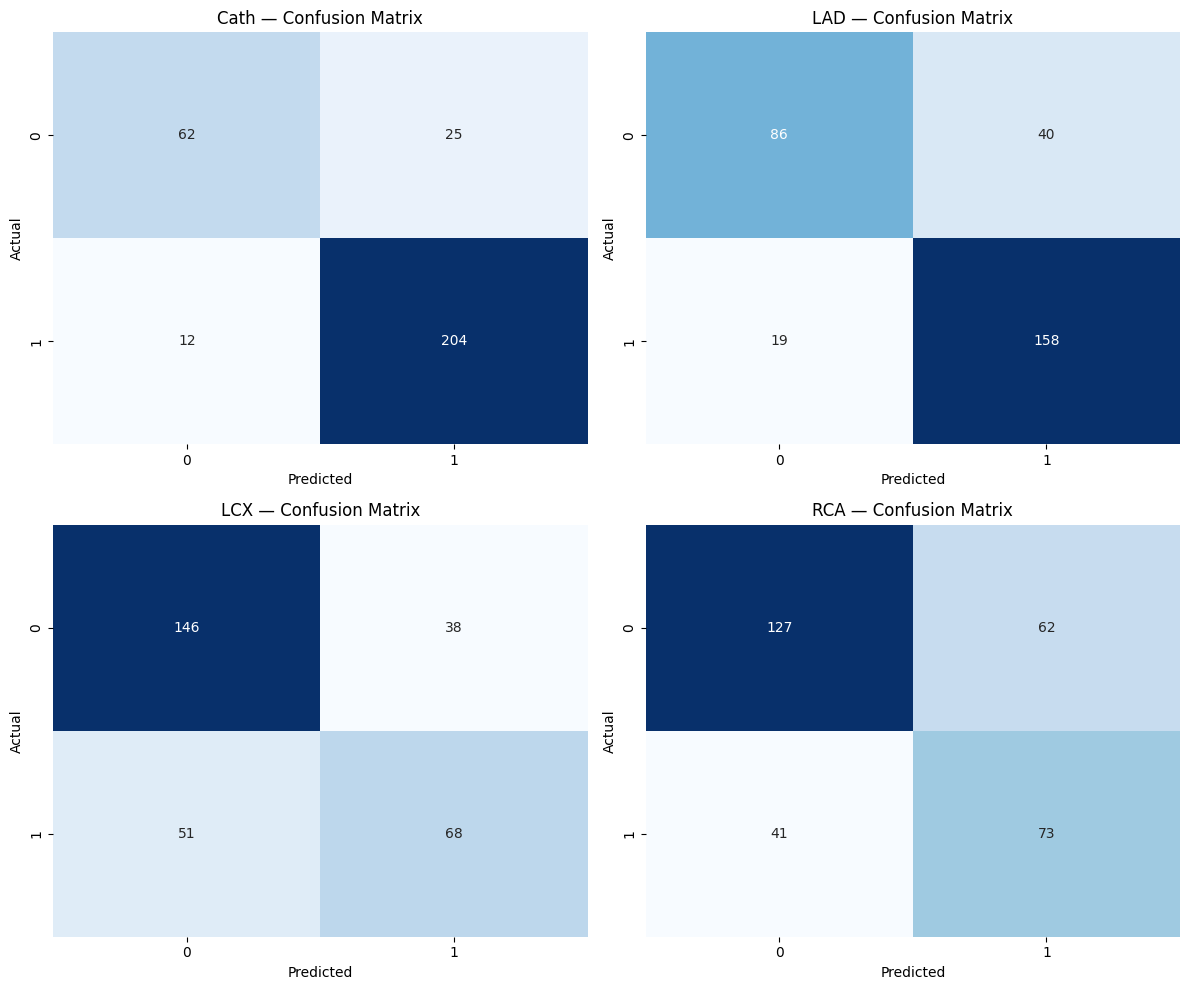

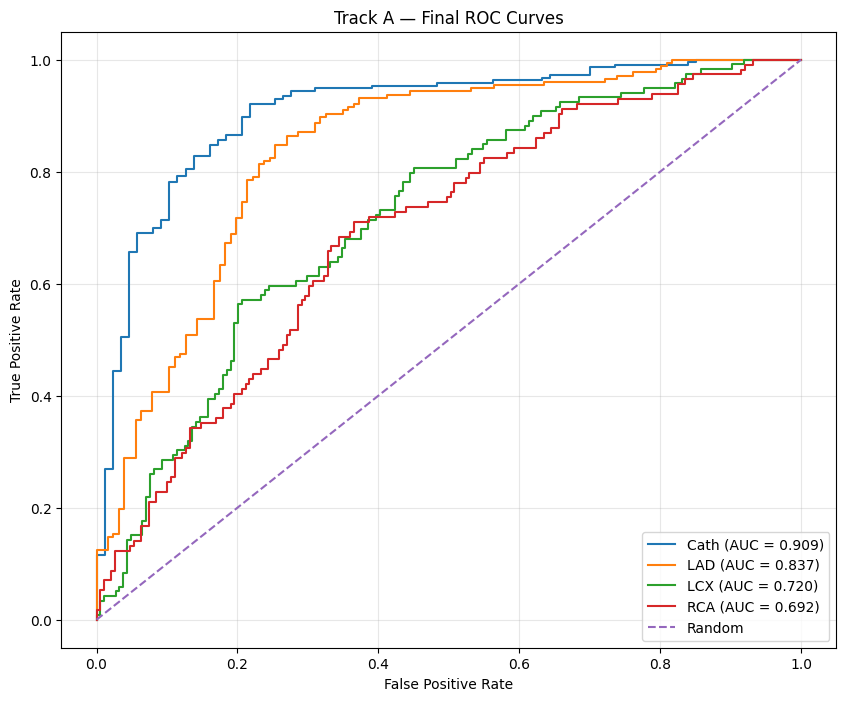

In [122]:
# ============================================================
# FINAL VALIDATION — METRICS + CONFUSION MATRICES + ROC CURVES
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

# ------------------------------------------------------------
# Store final validation results
# ------------------------------------------------------------

final_validation = []

# Store predictions for later use
cv_predictions = {}

# ------------------------------------------------------------
# Evaluate each final model using 5-fold CV
# ------------------------------------------------------------

for target, model in final_models.items():

    print(f"Evaluating {target}...")

    # Cross-validated probabilities
    cv_prob = cross_val_predict(
        model,
        X_final,
        y[target],
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]

    # Convert probabilities to predictions
    cv_pred = (cv_prob >= 0.5).astype(int)

    cv_predictions[target] = {
        "y_true": y[target].values,
        "y_pred": cv_pred,
        "y_prob": cv_prob
    }

    final_validation.append({
        "Target": target,
        "Model": {
            "Cath": "Tuned XGBoost",
            "LAD": "Extra Trees",
            "LCX": "Tuned XGBoost",
            "RCA": "Logistic Regression"
        }[target],
        "Accuracy": accuracy_score(y[target], cv_pred),
        "Precision": precision_score(y[target], cv_pred, zero_division=0),
        "Recall": recall_score(y[target], cv_pred, zero_division=0),
        "F1": f1_score(y[target], cv_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y[target], cv_prob)
    })


# ------------------------------------------------------------
# Results table
# ------------------------------------------------------------

final_validation_df = pd.DataFrame(final_validation)

print("\nFINAL CROSS-VALIDATED RESULTS")
display(final_validation_df.round(4))


# ============================================================
# CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, target in zip(axes.ravel(), cv_predictions.keys()):

    cm = confusion_matrix(
        cv_predictions[target]["y_true"],
        cv_predictions[target]["y_pred"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax
    )

    ax.set_title(f"{target} — Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


# ============================================================
# ROC CURVES
# ============================================================

plt.figure(figsize=(10, 8))

for target in cv_predictions:

    y_true = cv_predictions[target]["y_true"]
    y_prob = cv_predictions[target]["y_prob"]

    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{target} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Track A — Final ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [123]:
!pip install -q shap

import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [124]:
# ============================================================
# SHAP PREPARATION FOR ALL 4 FINAL MODELS
# ============================================================

import shap
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Transform input data using the fitted preprocessors
# ------------------------------------------------------------

shap_data = {}

for target, model in trained_models.items():

    print(f"Preparing SHAP data for {target}...")

    # Get fitted preprocessing step
    fitted_preprocessor = model.named_steps["preprocessor"]

    # Transform X
    X_transformed = fitted_preprocessor.transform(X_final)

    # Get transformed feature names
    feature_names = fitted_preprocessor.get_feature_names_out()

    shap_data[target] = {
        "X_transformed": X_transformed,
        "feature_names": feature_names
    }

print("\nSHAP preparation completed.")

for target in shap_data:
    print(
        target,
        "→",
        shap_data[target]["X_transformed"].shape
    )

Preparing SHAP data for Cath...
Preparing SHAP data for LAD...
Preparing SHAP data for LCX...
Preparing SHAP data for RCA...

SHAP preparation completed.
Cath → (303, 77)
LAD → (303, 77)
LCX → (303, 77)
RCA → (303, 77)


In [125]:
# ============================================================
# CREATE SHAP EXPLAINERS
# ============================================================

shap_explanations = {}

for target, model in trained_models.items():

    print(f"Creating SHAP explainer for {target}...")

    classifier = model.named_steps["classifier"]

    X_transformed = shap_data[target]["X_transformed"]
    feature_names = shap_data[target]["feature_names"]

    # Tree-based models
    if target in ["Cath", "LAD", "LCX"]:

        explainer = shap.TreeExplainer(
            classifier
        )

        shap_values = explainer.shap_values(
            X_transformed
        )

    # Logistic Regression
    else:

        explainer = shap.LinearExplainer(
            classifier,
            X_transformed
        )

        shap_values = explainer.shap_values(
            X_transformed
        )

    shap_explanations[target] = {
        "explainer": explainer,
        "shap_values": shap_values,
        "feature_names": feature_names,
        "X_transformed": X_transformed
    }

    print(f"{target} SHAP completed.")

print("\nAll SHAP explanations generated.")

Creating SHAP explainer for Cath...
Cath SHAP completed.
Creating SHAP explainer for LAD...


Background dataset has 303 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=303 when initializing the masker.


LAD SHAP completed.
Creating SHAP explainer for LCX...
LCX SHAP completed.
Creating SHAP explainer for RCA...
RCA SHAP completed.

All SHAP explanations generated.


In [126]:
# ============================================================
# GLOBAL SHAP FEATURE IMPORTANCE — FIXED FOR ALL MODELS
# ============================================================

for target, data in shap_explanations.items():

    print("\n" + "=" * 70)
    print(f"{target} — GLOBAL FEATURE IMPORTANCE")
    print("=" * 70)

    shap_values = data["shap_values"]
    feature_names = data["feature_names"]

    # --------------------------------------------------------
    # Handle all SHAP output formats
    # --------------------------------------------------------

    if isinstance(shap_values, list):

        # Binary classification returned as [class_0, class_1]
        values = np.asarray(shap_values[1])

    else:

        values = np.asarray(shap_values)

        # Possible shape:
        # (samples, features)
        if values.ndim == 2:
            pass

        # Possible shape:
        # (samples, features, classes)
        elif values.ndim == 3:

            # Use positive class (class 1)
            values = values[:, :, 1]

        else:
            raise ValueError(
                f"Unexpected SHAP shape for {target}: "
                f"{values.shape}"
            )

    # --------------------------------------------------------
    # Mean absolute SHAP value
    # --------------------------------------------------------

    mean_abs_shap = np.abs(values).mean(axis=0)

    # Make sure dimensions match
    if len(feature_names) != len(mean_abs_shap):

        print(
            f"Dimension mismatch for {target}: "
            f"{len(feature_names)} feature names vs "
            f"{len(mean_abs_shap)} SHAP values"
        )

        continue

    # --------------------------------------------------------
    # Importance dataframe
    # --------------------------------------------------------

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Mean |SHAP|": mean_abs_shap
    })

    importance_df = (
        importance_df
        .sort_values(
            "Mean |SHAP|",
            ascending=False
        )
        .head(15)
        .reset_index(drop=True)
    )

    display(
        importance_df.round(5)
    )


Cath — GLOBAL FEATURE IMPORTANCE


,Feature,Mean |SHAP|
0,num__Typical Chest Pain,1.29970
1,num__EF-TTE,0.69250
2,num__Age,0.55239
3,num__FBS,0.47149
4,num__TG,0.45786
5,num__Region RWMA,0.43405
6,num__ESR,0.29202
7,num__HTN,0.27859
8,num__Tinversion,0.27389
9,num__BP,0.25897



LAD — GLOBAL FEATURE IMPORTANCE


,Feature,Mean |SHAP|
0,num__Typical Chest Pain,0.09288
1,num__Region RWMA,0.04301
2,cat__Atypical_N,0.04034
3,cat__Atypical_Y,0.03630
4,num__Tinversion,0.02693
5,num__EF-TTE,0.02509
6,num__HTN,0.02458
7,num__Age,0.02105
8,num__St Depression,0.01771
9,cat__Nonanginal_N,0.01239



LCX — GLOBAL FEATURE IMPORTANCE


,Feature,Mean |SHAP|
0,num__Age,0.49058
1,num__Typical Chest Pain,0.45528
2,num__CR,0.33096
3,num__TG,0.32960
4,num__PLT,0.25776
5,num__FBS,0.22432
6,num__Na,0.21632
7,num__HDL,0.20178
8,num__Length,0.19489
9,num__ESR,0.17432



RCA — GLOBAL FEATURE IMPORTANCE


,Feature,Mean |SHAP|
0,num__DM,0.74996
1,num__Age,0.59982
2,num__ESR,0.41157
3,num__Weight,0.39831
4,num__Function Class,0.39440
5,num__Typical Chest Pain,0.38832
6,num__BUN,0.34162
7,cat__Sex_Fmale,0.31539
8,cat__Sex_Male,0.30034
9,num__Neut,0.29393



SHAP Summary — Cath


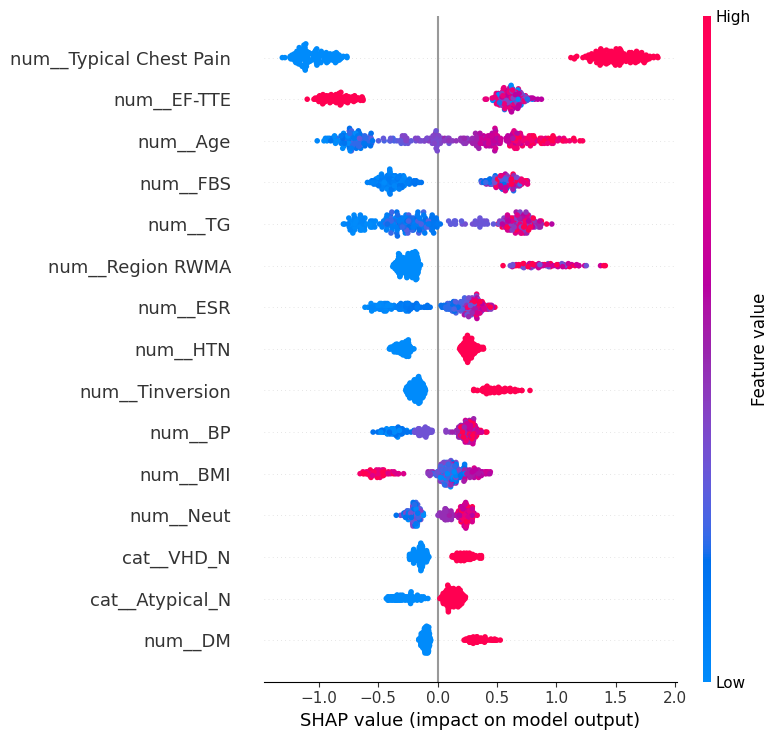


SHAP Summary — LAD


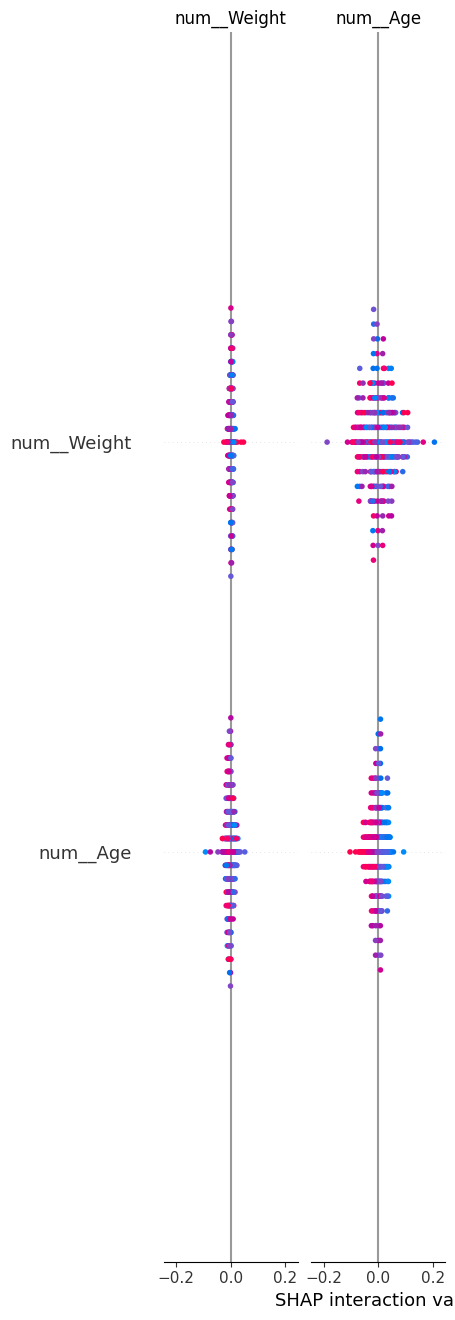


SHAP Summary — LCX


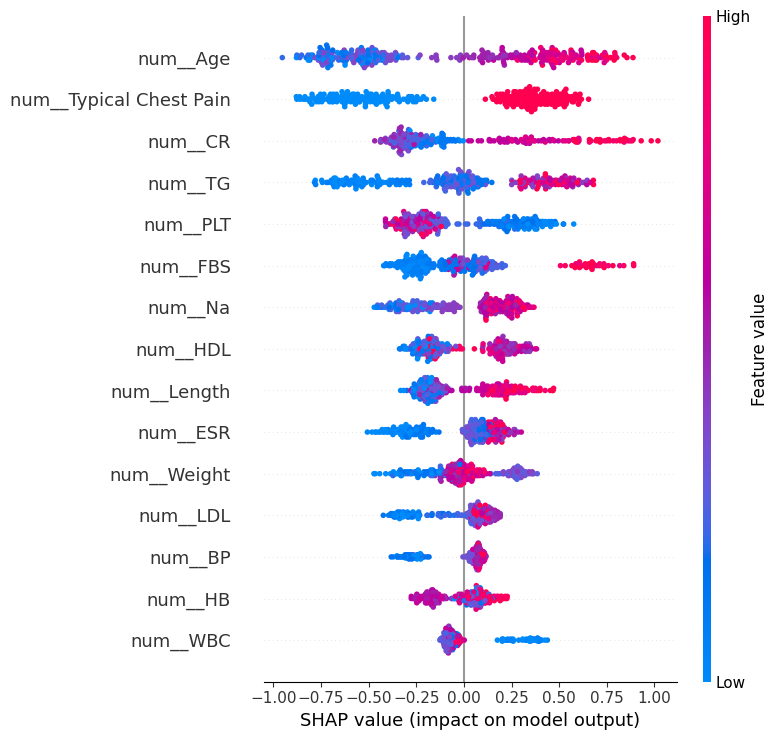


SHAP Summary — RCA


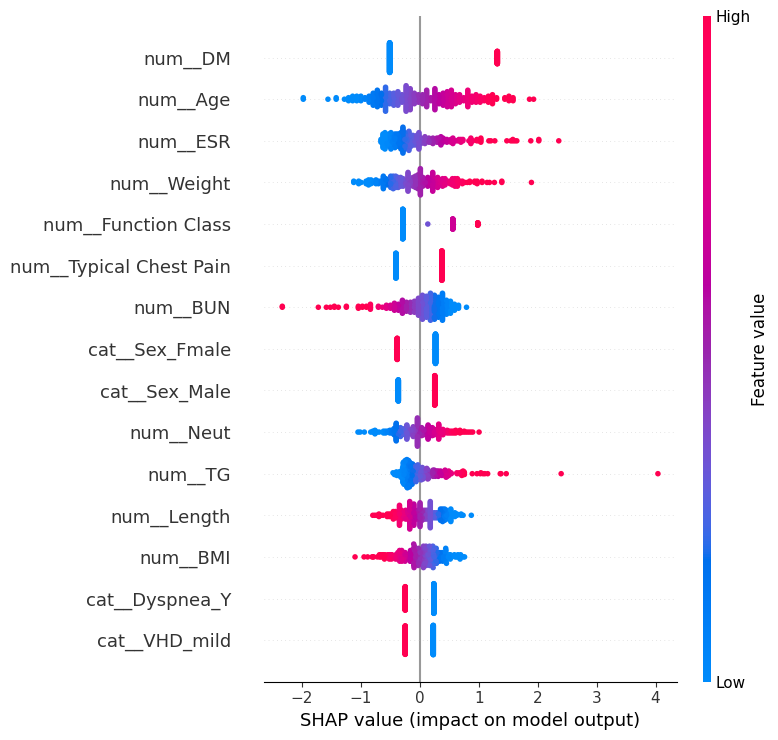

In [127]:
# ============================================================
# SHAP SUMMARY PLOTS
# ============================================================

for target, data in shap_explanations.items():

    shap_values = data["shap_values"]
    feature_names = data["feature_names"]
    X_transformed = data["X_transformed"]

    if isinstance(shap_values, list):
        values = shap_values[1]
    else:
        values = shap_values

    print(f"\nSHAP Summary — {target}")

    shap.summary_plot(
        values,
        X_transformed,
        feature_names=feature_names,
        max_display=15,
        show=True
    )

In [128]:
# ============================================================
# INDIVIDUAL PATIENT SHAP EXPLANATION
# ============================================================

patient_index = 0   # Change this to 1, 2, 3, ... for another patient

print("=" * 70)
print(f"PATIENT {patient_index} — AI EXPLANATION")
print("=" * 70)

patient_explanations = {}

for target, data in shap_explanations.items():

    shap_values = np.asarray(data["shap_values"])
    feature_names = data["feature_names"]

    # --------------------------------------------------------
    # Handle SHAP output format
    # --------------------------------------------------------

    if isinstance(data["shap_values"], list):

        values = np.asarray(
            data["shap_values"][1]
        )

    else:

        values = shap_values

        if values.ndim == 3:
            values = values[:, :, 1]

    # --------------------------------------------------------
    # Patient SHAP values
    # --------------------------------------------------------

    patient_shap = values[patient_index]

    patient_df = pd.DataFrame({
        "Feature": feature_names,
        "SHAP Value": patient_shap
    })

    # Absolute importance
    patient_df["Absolute SHAP"] = (
        patient_df["SHAP Value"].abs()
    )

    # Sort by strongest contribution
    patient_df = (
        patient_df
        .sort_values(
            "Absolute SHAP",
            ascending=False
        )
        .head(10)
        .reset_index(drop=True)
    )

    patient_explanations[target] = patient_df

    print(f"\n{target}")
    display(
        patient_df[
            ["Feature", "SHAP Value"]
        ].round(5)
    )

PATIENT 0 — AI EXPLANATION

Cath


,Feature,SHAP Value
0,num__Typical Chest Pain,-0.91636
1,num__TG,0.75800
2,num__EF-TTE,0.72395
3,num__Tinversion,0.56846
4,num__BMI,0.40864
5,num__BP,-0.39626
6,num__K,0.35496
7,num__FBS,-0.32687
8,num__ESR,-0.31530
9,num__Age,-0.29846



LAD


,Feature,SHAP Value
0,num__St Depression,0.08473
1,num__Tinversion,0.07535
2,num__Typical Chest Pain,-0.07043
3,num__HTN,0.04637
4,cat__Atypical_N,0.03493
5,cat__Atypical_Y,0.02914
6,num__Region RWMA,-0.02137
7,cat__VHD_N,0.02000
8,num__Current Smoker,0.01831
9,num__LDL,0.01686



LCX


,Feature,SHAP Value
0,num__Typical Chest Pain,-0.87919
1,num__Age,-0.62363
2,num__PLT,-0.32851
3,num__BUN,0.32372
4,num__TG,0.32045
5,num__BP,-0.28827
6,num__ESR,-0.27479
7,num__HDL,-0.27352
8,num__FBS,-0.23592
9,num__Length,0.19865



RCA


,Feature,SHAP Value
0,num__BUN,0.65632
1,num__Weight,0.63776
2,num__DM,-0.51130
3,num__TG,0.49033
4,num__ESR,-0.45557
5,num__Typical Chest Pain,-0.40519
6,num__Current Smoker,0.37652
7,num__Age,-0.37196
8,num__CR,-0.34998
9,num__Length,-0.34484


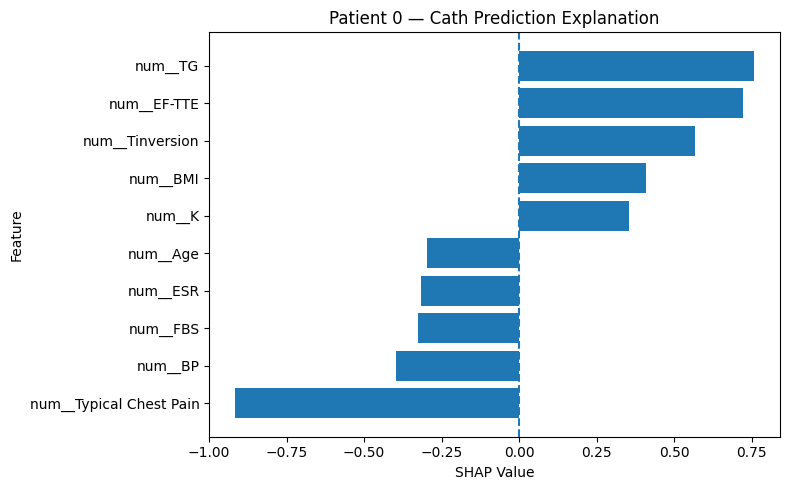

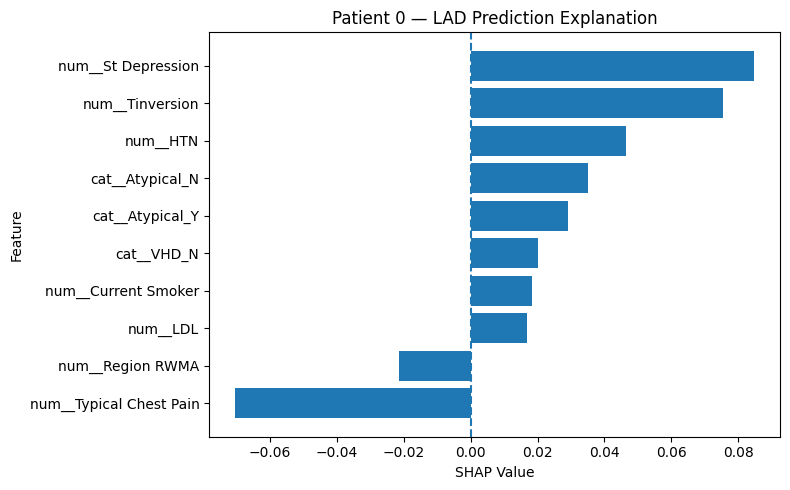

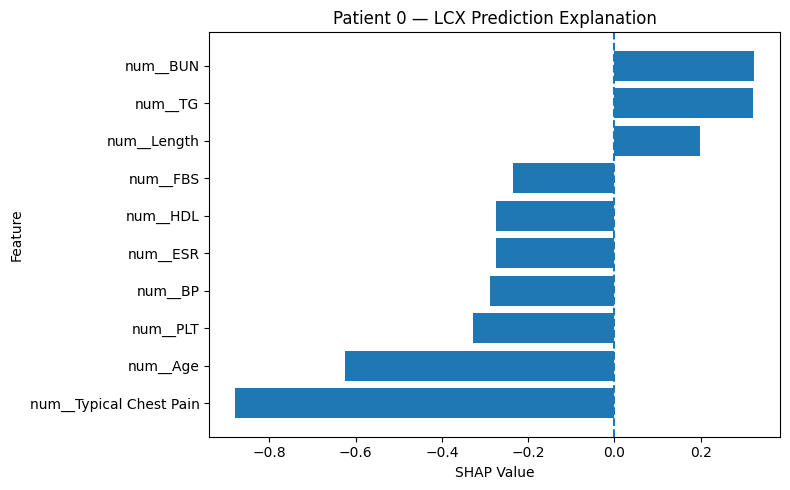

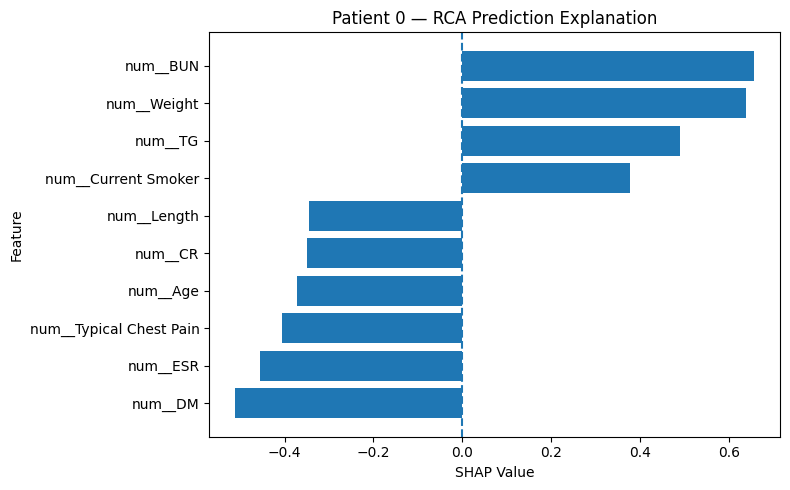

In [129]:
# ============================================================
# PATIENT-LEVEL SHAP BAR CHARTS
# ============================================================

for target, explanation in patient_explanations.items():

    plot_df = explanation.sort_values(
        "SHAP Value"
    )

    plt.figure(figsize=(8, 5))

    plt.barh(
        plot_df["Feature"],
        plot_df["SHAP Value"]
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.title(
        f"Patient {patient_index} — {target} Prediction Explanation"
    )

    plt.xlabel(
        "SHAP Value"
    )

    plt.ylabel(
        "Feature"
    )

    plt.tight_layout()
    plt.show()

In [130]:
# ============================================================
# PATIENT RISK SUMMARY
# ============================================================

patient_risk = {
    "CAD": prediction_output.loc[
        patient_index, "Cath_Probability"
    ],

    "LAD Stenosis": prediction_output.loc[
        patient_index, "LAD_Probability"
    ],

    "LCX Stenosis": prediction_output.loc[
        patient_index, "LCX_Probability"
    ],

    "RCA Stenosis": prediction_output.loc[
        patient_index, "RCA_Probability"
    ]
}

risk_summary = pd.DataFrame({
    "Prediction": patient_risk.keys(),
    "Probability": patient_risk.values()
})

risk_summary["Risk (%)"] = (
    risk_summary["Probability"] * 100
).round(2)

risk_summary["Prediction"] = [
    "CAD",
    "LAD Stenosis",
    "LCX Stenosis",
    "RCA Stenosis"
]

display(
    risk_summary[
        ["Prediction", "Risk (%)"]
    ]
)

,Prediction,Risk (%)
0,CAD,92.81
1,LAD Stenosis,93.07
2,LCX Stenosis,10.68
3,RCA Stenosis,43.89


In [131]:
# ============================================================
# 3D CORONARY VISUALIZATION DATA
# ============================================================

patient_index = 0

coronary_risk = {
    "LAD": float(
        prediction_output.loc[
            patient_index, "LAD_Probability"
        ]
    ),

    "LCX": float(
        prediction_output.loc[
            patient_index, "LCX_Probability"
        ]
    ),

    "RCA": float(
        prediction_output.loc[
            patient_index, "RCA_Probability"
        ]
    ),

    "CAD": float(
        prediction_output.loc[
            patient_index, "Cath_Probability"
        ]
    )
}

print("Patient:", patient_index)
print()

for vessel, probability in coronary_risk.items():
    print(
        f"{vessel}: {probability:.2%}"
    )

Patient: 0

LAD: 93.07%
LCX: 10.68%
RCA: 43.89%
CAD: 92.81%


In [132]:
# ============================================================
# INTERACTIVE 3D CORONARY VESSEL VISUALIZATION
# ============================================================

import plotly.graph_objects as go
import numpy as np

# ------------------------------------------------------------
# Risk → visual properties
# ------------------------------------------------------------

def risk_color(probability):

    if probability < 0.30:
        return "green"

    elif probability < 0.70:
        return "orange"

    else:
        return "red"


def risk_label(probability):

    if probability < 0.30:
        return "LOW"

    elif probability < 0.70:
        return "MODERATE"

    else:
        return "HIGH"


# ------------------------------------------------------------
# Approximate 3D coronary paths
# ------------------------------------------------------------

vessels = {

    "LAD": {
        "x": [0.0, -0.15, -0.25, -0.30, -0.35],
        "y": [0.0, -0.20, -0.45, -0.70, -0.95],
        "z": [0.45, 0.35, 0.20, 0.05, -0.15]
    },

    "LCX": {
        "x": [0.0, 0.20, 0.45, 0.70, 0.90],
        "y": [0.0, 0.05, 0.10, 0.05, -0.05],
        "z": [0.45, 0.40, 0.35, 0.30, 0.25]
    },

    "RCA": {
        "x": [0.0, 0.30, 0.55, 0.70, 0.65],
        "y": [0.0, 0.20, 0.35, 0.25, 0.05],
        "z": [0.40, 0.20, 0.00, -0.20, -0.40]
    }
}


# ------------------------------------------------------------
# Create figure
# ------------------------------------------------------------

fig = go.Figure()


# ------------------------------------------------------------
# Add coronary vessels
# ------------------------------------------------------------

for vessel, coords in vessels.items():

    probability = coronary_risk[vessel]

    color = risk_color(probability)

    risk = risk_label(probability)

    fig.add_trace(
        go.Scatter3d(
            x=coords["x"],
            y=coords["y"],
            z=coords["z"],

            mode="lines+markers",

            line=dict(
                color=color,
                width=12
            ),

            marker=dict(
                size=5,
                color=color
            ),

            name=vessel,

            text=[
                f"{vessel}<br>"
                f"Risk: {probability:.2%}<br>"
                f"Status: {risk}"
            ] * len(coords),

            hoverinfo="text"
        )
    )


# ------------------------------------------------------------
# Add central heart point
# ------------------------------------------------------------

fig.add_trace(
    go.Scatter3d(
        x=[0],
        y=[0],
        z=[0.45],

        mode="markers+text",

        marker=dict(
            size=18,
            color="crimson"
        ),

        text=[
            f"CAD<br>{coronary_risk['CAD']:.2%}"
        ],

        textposition="top center",

        name="CAD"
    )
)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

fig.update_layout(

    title=(
        f"Patient {patient_index} — "
        f"3D Coronary Risk Visualization"
    ),

    scene=dict(

        xaxis=dict(
            visible=False
        ),

        yaxis=dict(
            visible=False
        ),

        zaxis=dict(
            visible=False
        ),

        aspectmode="manual",

        aspectratio=dict(
            x=1,
            y=1,
            z=1
        )
    ),

    width=900,
    height=700,

    legend=dict(
        title="Coronary Vessel"
    )
)


fig.show()

In [133]:
# ============================================================
# FRONTEND-READY PATIENT DATA
# ============================================================

import json
import numpy as np
import pandas as pd

frontend_patients = []

for patient_idx in range(len(df)):

    patient = {
        "patient_id": int(patient_idx + 1),

        "risk": {
            "cad": round(
                float(prediction_output.loc[
                    patient_idx, "Cath_Probability"
                ]), 4
            ),

            "lad": round(
                float(prediction_output.loc[
                    patient_idx, "LAD_Probability"
                ]), 4
            ),

            "lcx": round(
                float(prediction_output.loc[
                    patient_idx, "LCX_Probability"
                ]), 4
            ),

            "rca": round(
                float(prediction_output.loc[
                    patient_idx, "RCA_Probability"
                ]), 4
            )
        },

        "prediction": {
            "cad": int(
                prediction_output.loc[
                    patient_idx, "Cath_Prediction"
                ]
            ),

            "lad": int(
                prediction_output.loc[
                    patient_idx, "LAD_Prediction"
                ]
            ),

            "lcx": int(
                prediction_output.loc[
                    patient_idx, "LCX_Prediction"
                ]
            ),

            "rca": int(
                prediction_output.loc[
                    patient_idx, "RCA_Prediction"
                ]
            )
        }
    }

    frontend_patients.append(patient)


# ------------------------------------------------------------
# Save JSON
# ------------------------------------------------------------

with open(
    "cardiovascular_predictions.json",
    "w"
) as f:

    json.dump(
        frontend_patients,
        f,
        indent=2
    )


print(
    "Created cardiovascular_predictions.json"
)

print(
    f"Patients included: {len(frontend_patients)}"
)

print("\nExample patient:")
print(
    json.dumps(
        frontend_patients[0],
        indent=2
    )
)

Created cardiovascular_predictions.json
Patients included: 303

Example patient:
{
  "patient_id": 1,
  "risk": {
    "cad": 0.9281,
    "lad": 0.9307,
    "lcx": 0.1068,
    "rca": 0.4389
  },
  "prediction": {
    "cad": 1,
    "lad": 1,
    "lcx": 0,
    "rca": 0
  }
}


In [134]:
# ============================================================
# FRONTEND SHAP EXPLANATIONS
# ============================================================

import json
import numpy as np

frontend_shap = {}

for target, data in shap_explanations.items():

    shap_values = np.asarray(
        data["shap_values"]
    )

    # Handle binary SHAP formats
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, 1]

    elif isinstance(data["shap_values"], list):
        shap_values = np.asarray(
            data["shap_values"][1]
        )

    feature_names = data["feature_names"]

    target_data = {}

    for patient_idx in range(len(X_final)):

        patient_values = shap_values[patient_idx]

        importance = []

        for feature, value in zip(
            feature_names,
            patient_values
        ):

            importance.append({
                "feature": str(feature),
                "shap_value": round(
                    float(value),
                    5
                )
            })

        # strongest features
        importance = sorted(
            importance,
            key=lambda x: abs(x["shap_value"]),
            reverse=True
        )[:10]

        target_data[str(patient_idx + 1)] = importance

    frontend_shap[target] = target_data


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

with open(
    "cardiovascular_shap.json",
    "w"
) as f:

    json.dump(
        frontend_shap,
        f,
        indent=2
    )

print(
    "Created cardiovascular_shap.json"
)

Created cardiovascular_shap.json
